# Resultado final de análise gráfica exploratória dos dados brutos e limpos usados no processo de preparo da base de dados final
No processo cíclico de análise exploratório verificamos as dimensões abaixo com o intuito de entender melhor a disposição dos dados. A ideia aqui é apresentar um consolidado dos resultados finais de visualizações que foram analisadas ao longo do processo de seleçao e limpeza das dimensões.

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr

sns.set_theme(style="whitegrid", palette="deep")

raiz_projeto = next(
    (
        caminho
        for caminho in (Path.cwd(), *Path.cwd().parents)
        if (caminho / "1-limpeza/dados/dados_limpos/adult25_limpo.csv").is_file()
        and (caminho / "1-limpeza/dados/dados_selecionados/adult25_selecionados.csv").is_file()
    ),
    None,
)
if raiz_projeto is None:
    raise FileNotFoundError(
        f"Não encontrei os CSVs esperados a partir de {Path.cwd()}. "
        "Verifique se os arquivos de dados estão presentes no repositório."
    )

arquivo_base_limpo = raiz_projeto / "1-limpeza/dados/dados_limpos/adult25_limpo.csv"
arquivo_base_bruto = raiz_projeto / "1-limpeza/dados/dados_selecionados/adult25_selecionados.csv"


df = pd.read_csv(arquivo_base_limpo, low_memory=False)
print(f"Dimensões da base: {df.shape[0]:,} registros x {df.shape[1]} colunas")

df_bruto = pd.read_csv(arquivo_base_bruto, low_memory=False)
print(f"Dimensões da base: {df_bruto.shape[0]:,} registros x {df_bruto.shape[1]} colunas")

Dimensões da base: 24,215 registros x 73 colunas
Dimensões da base: 24,215 registros x 73 colunas


## Plotando Disposição de NANs nos dados bruto

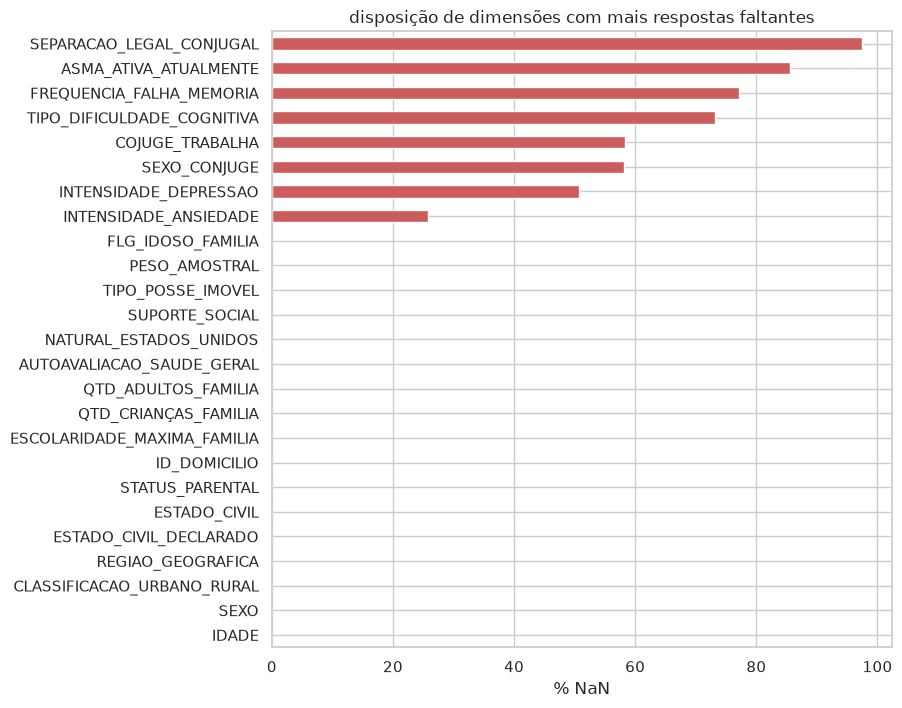

In [11]:
# Plotando disposição de dimensões nan
pct = df_bruto.isna().mean().mul(100).sort_values(ascending=False).head(25)
pct.sort_values().plot(kind="barh", figsize=(8, 8), color="indianred")
plt.title('disposição de dimensões com mais respostas faltantes')
plt.xlabel("% NaN"); plt.show()

## Plotando Disposição de Genero

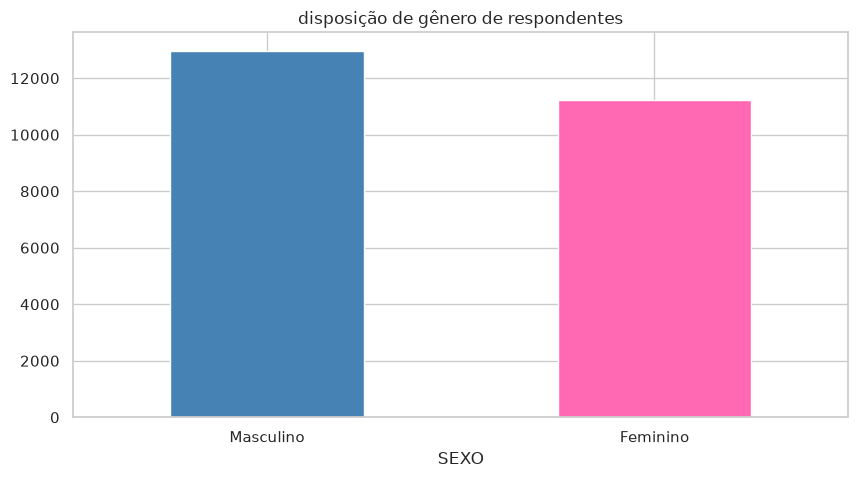

In [12]:
# Plotando disposição de gênero
dct_genero = df["SEXO"].map({1: "Feminino", 2: "Masculino"})

plt.figure(figsize=(10, 5))
dct_genero.value_counts().plot(kind="bar", color=["steelblue", "hotpink"])
plt.xticks(rotation=0)
plt.title('disposição de gênero de respondentes')
plt.show()


## Plotando Disposição de Idade

<Axes: xlabel='IDADE'>

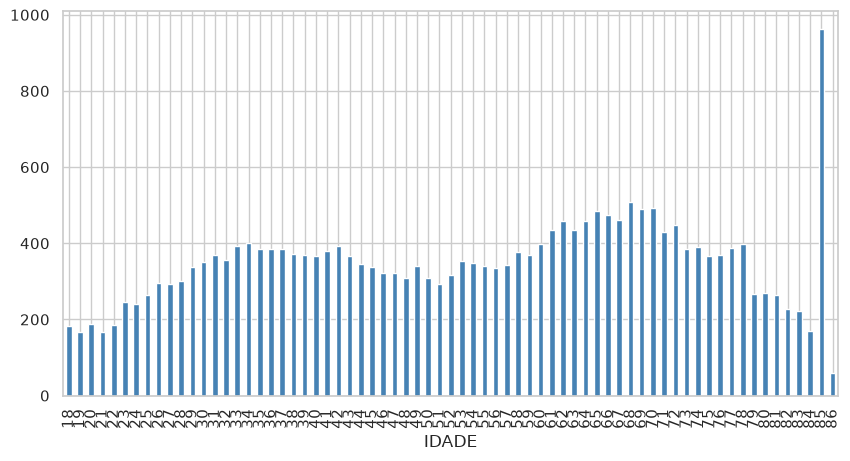

In [13]:


#Plotando disposição de idade
plt.figure(figsize=(6, 5))
df["IDADE"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)


## Plotando Disposição Geográfica de respondentes

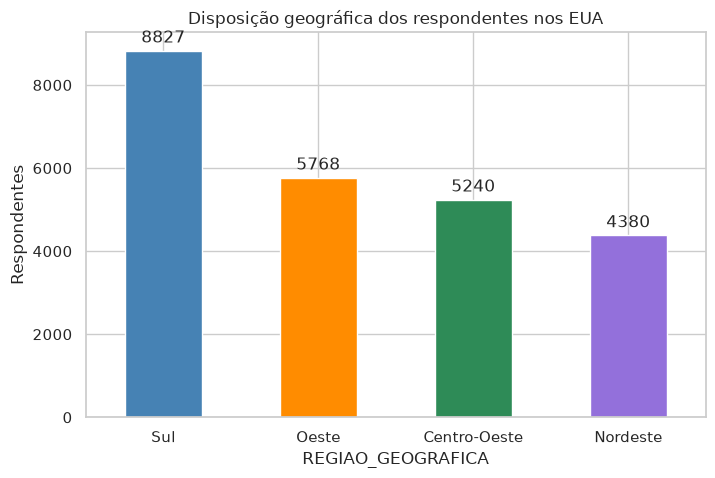

In [14]:

# Plotando disposição geográfica
mapa_regiao = {1: "Nordeste", 2: "Centro-Oeste", 3: "Sul", 4: "Oeste"}

plt.figure(figsize=(8, 5))
(df["REGIAO_GEOGRAFICA"]
    .map(mapa_regiao)
    .value_counts()
    .plot(kind="bar", color=["steelblue", "darkorange", "seagreen", "mediumpurple"]))
plt.ylabel("Respondentes")
plt.bar_label(plt.gca().containers[0],padding=3)
plt.xticks(rotation=0)
plt.title("Disposição geográfica dos respondentes nos EUA")
plt.show()

## Distribuição da severidade de depressão por gênero

A categoria de severidade PHQ é ordinal (códigos de 1 a 4). As barras empilhadas mostram o percentual de cada categoria dentro de cada gênero; respostas desconhecidas e códigos fora dessa faixa são excluídos.

In [ ]:
coluna_alvo_depressao = "SEVERIDADE_DEPRESSAO_PHQ"
dados_depressao = df[["SEXO", "IDADE", coluna_alvo_depressao]].apply(
    pd.to_numeric, errors="coerce"
)
dados_depressao = dados_depressao.loc[
    dados_depressao[coluna_alvo_depressao].isin([1, 2, 3, 4])
].copy()
dados_depressao["GENERO"] = dados_depressao["SEXO"].map(
    {1: "Feminino", 2: "Masculino"}
)

dados_por_genero = dados_depressao.dropna(subset=["GENERO"])
print(f"Respostas válidas para gênero: {len(dados_por_genero):,}")

tabela_percentual_genero = pd.crosstab(
    dados_por_genero["GENERO"],
    dados_por_genero[coluna_alvo_depressao],
    normalize="index",
).reindex(index=["Feminino", "Masculino"], columns=[1, 2, 3, 4], fill_value=0)
tabela_percentual_genero.index.name = "Gênero"
tabela_percentual_genero.columns.name = "Severidade PHQ"
n_por_genero = dados_por_genero["GENERO"].value_counts().reindex(
    ["Feminino", "Masculino"], fill_value=0
)

fig, ax = plt.subplots(figsize=(8, 5))
tabela_percentual_genero.plot(
    kind="bar",
    stacked=True,
    color=["#4c78a8", "#f2cf5b", "#f58518", "#e45756"],
    ax=ax,
)
ax.set(
    title="Distribuição percentual da severidade PHQ por gênero",
    xlabel="Gênero",
    ylabel="Percentual de respostas",
    ylim=(0, 1),
    yticks=[0, 0.25, 0.5, 0.75, 1],
    yticklabels=["0%", "25%", "50%", "75%", "100%"],
)
ax.legend(title="Categoria PHQ", labels=["1", "2", "3", "4"], bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_xticklabels(
    [f"{genero}\n(n={n_por_genero[genero]:,})" for genero in n_por_genero.index],
    rotation=0,
)
fig.tight_layout()
plt.show()

## Distribuição da idade por severidade de depressão

O boxplot compara a distribuição de idade em cada categoria PHQ. São considerados somente códigos PHQ de 1 a 4 e idades válidas de 18 a 85 anos; respostas desconhecidas são excluídas.

In [ ]:
dados_por_idade = dados_depressao.loc[
    dados_depressao["IDADE"].between(18, 85)
].copy()
print(f"Respostas válidas para idade: {len(dados_por_idade):,}")

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=dados_por_idade,
    x=coluna_alvo_depressao,
    y="IDADE",
    order=[1, 2, 3, 4],
    showfliers=False,
    ax=ax,
)
ax.set(
    title="Distribuição da idade por categoria de severidade PHQ",
    xlabel="Categoria de severidade PHQ (código)",
    ylabel="Idade (anos)",
    xticks=[0, 1, 2, 3],
    xticklabels=[1, 2, 3, 4],
)
fig.tight_layout()
plt.show()

## Razão entre renda familiar e linha de pobreza por severidade de depressão

A variável `RAZAO_RENDA_POBREZA` compara a renda familiar com a linha de pobreza (não é renda em dólares) e valores iguais a 12 representam 12 ou mais. O boxplot mostra sua distribuição em cada categoria PHQ; as categorias desconhecidas do desfecho são excluídas.

In [ ]:
coluna_razao_renda = "RAZAO_RENDA_POBREZA"
dados_renda = df[[coluna_razao_renda, coluna_alvo_depressao]].apply(
    pd.to_numeric, errors="coerce"
)
dados_renda = dados_renda.loc[
    dados_renda[coluna_alvo_depressao].isin([1, 2, 3, 4])
].dropna(subset=[coluna_razao_renda]).copy()
n_por_phq_renda = dados_renda[coluna_alvo_depressao].value_counts().reindex(
    [1, 2, 3, 4], fill_value=0
)
print(f"Respostas válidas para renda: {len(dados_renda):,}")

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=dados_renda,
    x=coluna_alvo_depressao,
    y=coluna_razao_renda,
    order=[1, 2, 3, 4],
    showfliers=False,
    ax=ax,
)
ax.set(
    title="Razão renda/linha de pobreza por categoria PHQ",
    xlabel="Categoria de severidade PHQ (código)",
    ylabel="Razão renda familiar / linha de pobreza (12 = 12 ou mais)",
    xticks=[0, 1, 2, 3],
    xticklabels=[
        f"{categoria}\n(n={n_por_phq_renda[categoria]:,})"
        for categoria in [1, 2, 3, 4]
    ],
)
fig.tight_layout()
plt.show()

## Severidade de depressão por cobertura Medicare

As barras empilhadas comparam o percentual de cada categoria PHQ entre pessoas com e sem Medicare. O código `-1` (resposta desconhecida) é excluído; na variável limpa, `1` significa sim e `2`, não.

In [ ]:
coluna_medicare = "PLANO_PUBLICO"
dados_medicare = df[[coluna_medicare, coluna_alvo_depressao]].apply(
    pd.to_numeric, errors="coerce"
)
dados_medicare = dados_medicare.loc[
    dados_medicare[coluna_medicare].isin([1, 2])
    & dados_medicare[coluna_alvo_depressao].isin([1, 2, 3, 4])
].copy()
dados_medicare["MEDICARE"] = dados_medicare[coluna_medicare].map(
    {1: "Sim", 2: "Não"}
)
tabela_percentual_medicare = pd.crosstab(
    dados_medicare["MEDICARE"],
    dados_medicare[coluna_alvo_depressao],
    normalize="index",
).reindex(index=["Sim", "Não"], columns=[1, 2, 3, 4], fill_value=0)
n_por_medicare = dados_medicare["MEDICARE"].value_counts().reindex(
    ["Sim", "Não"], fill_value=0
)
print(f"Respostas válidas para Medicare: {len(dados_medicare):,}")

fig, ax = plt.subplots(figsize=(8, 5))
tabela_percentual_medicare.plot(
    kind="bar",
    stacked=True,
    color=["#4c78a8", "#f2cf5b", "#f58518", "#e45756"],
    ax=ax,
)
ax.set(
    title="Distribuição percentual da severidade PHQ por Medicare",
    xlabel="Cobertura Medicare",
    ylabel="Percentual de respostas",
    ylim=(0, 1),
    yticks=[0, 0.25, 0.5, 0.75, 1],
    yticklabels=["0%", "25%", "50%", "75%", "100%"],
)
ax.set_xticklabels(
    [f"{status}\n(n={n_por_medicare[status]:,})" for status in n_por_medicare.index],
    rotation=0,
)
ax.legend(
    title="Categoria PHQ",
    labels=["1", "2", "3", "4"],
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
fig.tight_layout()
plt.show()

## Severidade de depressão por nível de suporte social

As barras empilhadas comparam o percentual de cada categoria PHQ entre os níveis de suporte social. A escala vai de 1 (nunca) a 5 (sempre); respostas desconhecidas (`-1`) e categorias PHQ inválidas são excluídas.

In [ ]:
coluna_suporte_social = "SUPORTE_SOCIAL"
dados_suporte_social = df[[coluna_suporte_social, coluna_alvo_depressao]].apply(
    pd.to_numeric, errors="coerce"
)
dados_suporte_social = dados_suporte_social.loc[
    dados_suporte_social[coluna_suporte_social].isin([1, 2, 3, 4, 5])
    & dados_suporte_social[coluna_alvo_depressao].isin([1, 2, 3, 4])
].copy()
rotulos_suporte = {
    1: "Nunca",
    2: "Baixa frequência",
    3: "Intermediário",
    4: "Alta frequência",
    5: "Sempre",
}
dados_suporte_social["NIVEL_SUPORTE"] = dados_suporte_social[
    coluna_suporte_social
].map(rotulos_suporte)
ordem_suporte = list(rotulos_suporte.values())
tabela_percentual_suporte = pd.crosstab(
    dados_suporte_social["NIVEL_SUPORTE"],
    dados_suporte_social[coluna_alvo_depressao],
    normalize="index",
).reindex(index=ordem_suporte, columns=[1, 2, 3, 4], fill_value=0)
n_por_suporte = dados_suporte_social["NIVEL_SUPORTE"].value_counts().reindex(
    ordem_suporte, fill_value=0
)
print(f"Respostas válidas para suporte social: {len(dados_suporte_social):,}")

fig, ax = plt.subplots(figsize=(11, 5))
tabela_percentual_suporte.plot(
    kind="bar",
    stacked=True,
    color=["#4c78a8", "#f2cf5b", "#f58518", "#e45756"],
    ax=ax,
)
ax.set(
    title="Distribuição percentual da severidade PHQ por suporte social",
    xlabel="Frequência de suporte social",
    ylabel="Percentual de respostas",
    ylim=(0, 1),
    yticks=[0, 0.25, 0.5, 0.75, 1],
    yticklabels=["0%", "25%", "50%", "75%", "100%"],
)
ax.set_xticklabels(
    [
        f"{nivel}\n(n={n_por_suporte[nivel]:,})"
        for nivel in ordem_suporte
    ],
    rotation=0,
)
ax.legend(
    title="Categoria PHQ",
    labels=["1", "2", "3", "4"],
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
fig.tight_layout()
plt.show()